# Reproduction: Tshitoyan et al. (2019) on cs.IR, a historical backtest

Paper 12, IR 2 seminar. This notebook **reads cached artefacts** produced by the scripts in `ir2/scripts/`; each section names the command that regenerates them. Decisions and deviations are in `ir2/NOTES.md`.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display
IR2 = Path('.').resolve()
R, F = IR2 / 'results', IR2 / 'figures'
show = lambda p: display(Markdown((R / p).read_text()))

## Phase 1: dated corpus (Kaggle arXiv snapshot, 2026-11-08)
`python ir2/scripts/phase1_corpus.py`

,cs.IR (any),cs.IR (primary),cs.CL (any),cs.CL not cs.IR
year,,,,
2008,85,40,70,56
2009,161,87,91,80
2010,180,110,86,78
2011,201,119,125,113
2012,405,225,225,164
2013,386,215,334,273
2014,421,225,557,464
2015,495,244,832,718
2016,575,288,1692,1508


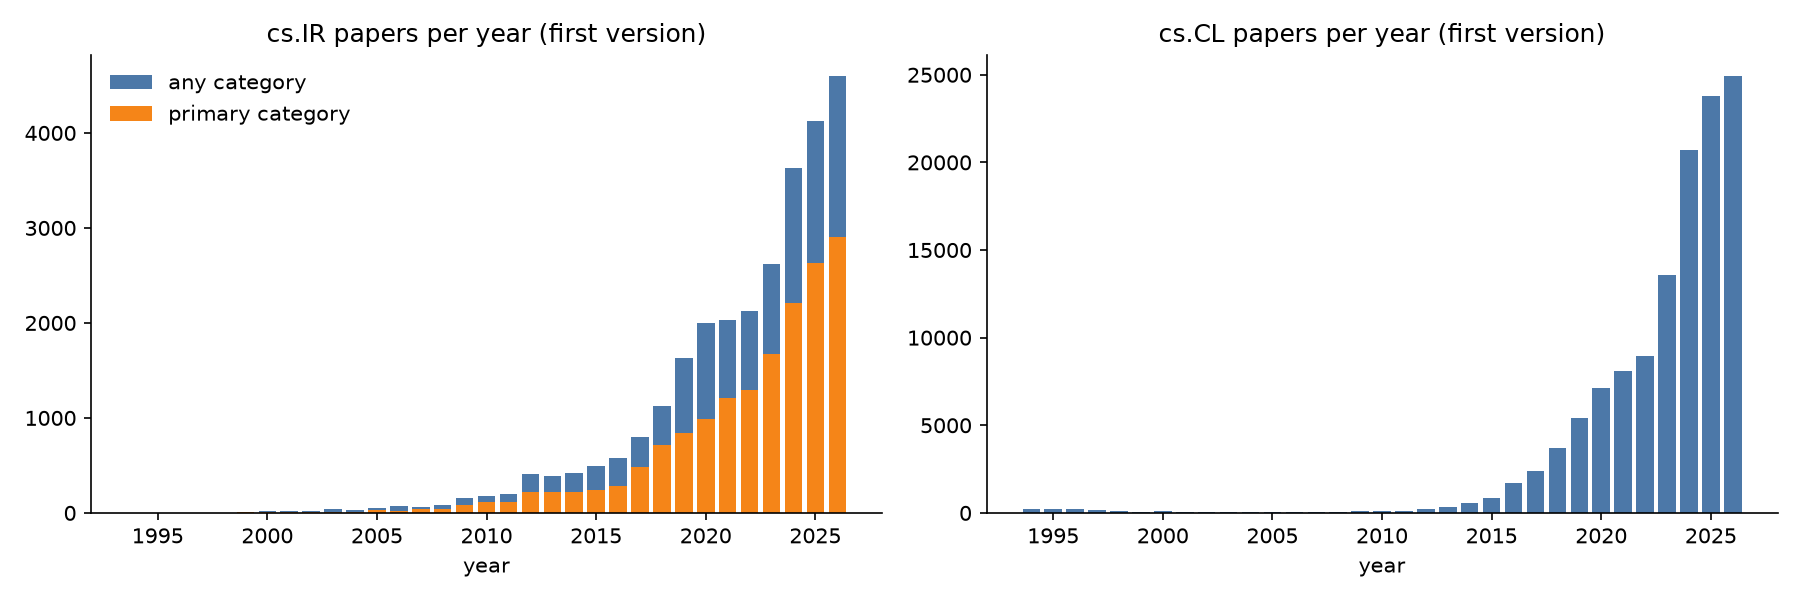

In [2]:
counts = pd.read_csv(R / 'phase1_counts.csv', index_col='year')
display(counts.loc[2008:])
display(Image(F / 'phase1_counts.png'))

## Phase 2: preprocessing with a phraser learned before each cutoff
`python ir2/scripts/phase2_preprocess.py`

In [3]:
show('phase2_cutoffs.md')

# Phase 2: per-cutoff preprocessing

- T=2016: 5,744 train docs (845,705 tokens), 25,267 post cs.IR docs, 1,673 phrasegrams, vocab 8,284 (890 phrases), 9s
- T=2017: 7,682 train docs (1,150,491 tokens), 24,692 post cs.IR docs, 2,403 phrasegrams, vocab 9,766 (1,293 phrases), 11s
- T=2018: 10,513 train docs (1,599,686 tokens), 23,898 post cs.IR docs, 3,338 phrasegrams, vocab 11,614 (1,817 phrases), 12s
- T=2019: 14,793 train docs (2,285,282 tokens), 22,771 post cs.IR docs, 4,626 phrasegrams, vocab 14,035 (2,583 phrases), 15s
- T=2020: 20,869 train docs (3,296,998 tokens), 21,140 post cs.IR docs, 6,418 phrasegrams, vocab 17,109 (3,603 phrases), 19s
- T=2021: 28,834 train docs (4,673,688 tokens), 19,142 post cs.IR docs, 8,523 phrasegrams, vocab 20,789 (4,809 phrases), 24s
- T=2022: 38,196 train docs (6,332,539 tokens), 17,112 post cs.IR docs, 10,833 phrasegrams, vocab 24,858 (6,168 phrases), 30s
- T=2023: 48,486 train docs (8,203,760 tokens), 14,987 post cs.IR docs, 13,084 phrasegrams, vocab 29,076 (7,519 phrases), 36s


## Phase 3: the backtest
`python ir2/scripts/phase3_train.py && python ir2/scripts/phase3_encode.py && python ir2/scripts/phase3_backtest.py && python ir2/scripts/phase3_report.py`

A (target, T) pair is scored only if the concept exists before T: an indicator in ≥ 20 pre-T cs.IR abstracts and in the word2vec vocabulary. Which pairs were scored, and why the others were not:

In [4]:
st = pd.read_csv(R / 'backtest_status.csv')
st.pivot(index='target', columns='T', values='pre_T_target_docs_ir')

T,2016,2017,2018,2019,2020,2021,2022,2023
target,,,,,,,,
conversational_search,0,1,4,6,17,44,82,119
dense_retrieval,0,0,0,0,1,7,54,128
learning_to_rank,17,31,47,74,114,169,220,267
query_expansion,65,78,92,112,136,167,191,212
recommender_systems,359,495,703,1014,1471,2034,2743,3565
retrieval_augmented_generation,0,1,1,1,1,1,5,12


In [5]:
st.pivot(index='target', columns='T', values='status')

T,2016,2017,2018,2019,2020,2021,2022,2023
target,,,,,,,,
conversational_search,fewer than 20 pre-T cs.IR abstracts,fewer than 20 pre-T cs.IR abstracts,fewer than 20 pre-T cs.IR abstracts,fewer than 20 pre-T cs.IR abstracts,fewer than 20 pre-T cs.IR abstracts,scored,scored,scored
dense_retrieval,fewer than 20 pre-T cs.IR abstracts,fewer than 20 pre-T cs.IR abstracts,fewer than 20 pre-T cs.IR abstracts,fewer than 20 pre-T cs.IR abstracts,fewer than 20 pre-T cs.IR abstracts,fewer than 20 pre-T cs.IR abstracts,scored,scored
learning_to_rank,fewer than 20 pre-T cs.IR abstracts,scored,scored,scored,scored,scored,scored,scored
query_expansion,scored,scored,scored,scored,scored,scored,scored,scored
recommender_systems,scored,scored,scored,scored,scored,scored,scored,scored
retrieval_augmented_generation,fewer than 20 pre-T cs.IR abstracts,fewer than 20 pre-T cs.IR abstracts,fewer than 20 pre-T cs.IR abstracts,fewer than 20 pre-T cs.IR abstracts,fewer than 20 pre-T cs.IR abstracts,fewer than 20 pre-T cs.IR abstracts,fewer than 20 pre-T cs.IR abstracts,fewer than 20 pre-T cs.IR abstracts


### Main table: word2vec next to random and frequency (professor's point 2)

In [6]:
show('backtest_table.md')

# Backtest: precision@k of word2vec (the paper's output·input score) next to random and frequency

word2vec: mean ± std over 3 seeds. random: mean of 1,000 random orders of the same candidates. frequency: candidates sorted by pre-T count. Base rate = share of all candidates found. A pair is scored only if the concept exists before T (an indicator in ≥ 20 pre-T cs.IR abstracts and in the vocabulary).

### Candidates: `all` (28 scored pairs)

| target | T | candidates | base rate | P@10 w2v | P@10 random | P@10 freq | P@20 w2v | P@20 random | P@20 freq | P@50 w2v | P@50 random | P@50 freq |
|---|---|--:|--:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| conversational_search | 2021 | 18,770 | 0.05 | 0.27 ± 0.15 | 0.06 | 0.50 | 0.27 ± 0.08 | 0.06 | 0.60 | 0.23 ± 0.02 | 0.05 | 0.66 |
| conversational_search | 2022 | 21,815 | 0.03 | 0.13 ± 0.06 | 0.02 | 0.30 | 0.10 ± 0.00 | 0.03 | 0.40 | 0.09 ± 0.01 | 0.03 | 0.44 |
| conversational_search | 2023 | 25,250 | 0.01 | 0.10 ± 0.00 | 0.01 | 0.50 | 0.07 ± 0.03 | 0.01 | 0.45 | 0.07 ± 0.02 | 0.01 | 0.34 |
| dense_retrieval | 2022 | 21,910 | 0.09 | 0.57 ± 0.15 | 0.08 | 0.90 | 0.45 ± 0.09 | 0.09 | 0.95 | 0.41 ± 0.05 | 0.09 | 0.80 |
| dense_retrieval | 2023 | 24,373 | 0.05 | 0.23 ± 0.06 | 0.05 | 0.70 | 0.20 ± 0.05 | 0.05 | 0.65 | 0.18 ± 0.03 | 0.05 | 0.68 |
| learning_to_rank | 2017 | 8,420 | 0.22 | 0.47 ± 0.06 | 0.22 | 0.70 | 0.55 ± 0.09 | 0.22 | 0.70 | 0.49 ± 0.03 | 0.22 | 0.72 |
| learning_to_rank | 2018 | 9,749 | 0.16 | 0.50 ± 0.10 | 0.17 | 0.50 | 0.48 ± 0.03 | 0.17 | 0.55 | 0.49 ± 0.04 | 0.16 | 0.66 |
| learning_to_rank | 2019 | 11,492 | 0.11 | 0.30 ± 0.17 | 0.11 | 0.30 | 0.38 ± 0.10 | 0.11 | 0.40 | 0.36 ± 0.02 | 0.11 | 0.48 |
| learning_to_rank | 2020 | 13,774 | 0.07 | 0.17 ± 0.06 | 0.06 | 0.40 | 0.18 ± 0.06 | 0.07 | 0.40 | 0.17 ± 0.03 | 0.06 | 0.46 |
| learning_to_rank | 2021 | 16,529 | 0.04 | 0.13 ± 0.06 | 0.04 | 0.20 | 0.18 ± 0.03 | 0.03 | 0.20 | 0.15 ± 0.01 | 0.03 | 0.30 |
| learning_to_rank | 2022 | 19,889 | 0.02 | 0.07 ± 0.06 | 0.02 | 0.30 | 0.07 ± 0.03 | 0.02 | 0.20 | 0.09 ± 0.02 | 0.02 | 0.24 |
| learning_to_rank | 2023 | 23,487 | 0.01 | 0.17 ± 0.06 | 0.02 | 0.20 | 0.20 ± 0.00 | 0.01 | 0.25 | 0.13 ± 0.02 | 0.01 | 0.22 |
| query_expansion | 2016 | 6,330 | 0.17 | 0.23 ± 0.06 | 0.17 | 0.50 | 0.28 ± 0.10 | 0.17 | 0.65 | 0.31 ± 0.03 | 0.17 | 0.76 |
| query_expansion | 2017 | 7,546 | 0.13 | 0.33 ± 0.06 | 0.14 | 0.70 | 0.35 ± 0.05 | 0.14 | 0.55 | 0.29 ± 0.06 | 0.14 | 0.72 |
| query_expansion | 2018 | 9,061 | 0.10 | 0.17 ± 0.12 | 0.10 | 0.60 | 0.20 ± 0.05 | 0.10 | 0.55 | 0.28 ± 0.04 | 0.11 | 0.66 |
| query_expansion | 2019 | 11,062 | 0.07 | 0.20 ± 0.00 | 0.07 | 0.50 | 0.18 ± 0.03 | 0.08 | 0.50 | 0.21 ± 0.02 | 0.07 | 0.56 |
| query_expansion | 2020 | 13,622 | 0.05 | 0.20 ± 0.10 | 0.05 | 0.40 | 0.22 ± 0.03 | 0.05 | 0.55 | 0.19 ± 0.01 | 0.05 | 0.60 |
| query_expansion | 2021 | 16,694 | 0.03 | 0.20 ± 0.10 | 0.04 | 0.20 | 0.23 ± 0.03 | 0.03 | 0.35 | 0.17 ± 0.01 | 0.03 | 0.40 |
| query_expansion | 2022 | 20,326 | 0.02 | 0.20 ± 0.00 | 0.02 | 0.10 | 0.22 ± 0.08 | 0.02 | 0.25 | 0.15 ± 0.01 | 0.02 | 0.42 |
| query_expansion | 2023 | 24,113 | 0.02 | 0.13 ± 0.06 | 0.02 | 0.10 | 0.10 ± 0.00 | 0.02 | 0.20 | 0.09 ± 0.03 | 0.02 | 0.34 |
| recommender_systems | 2016 | 4,026 | 0.56 | 0.47 ± 0.12 | 0.56 | 0.80 | 0.50 ± 0.05 | 0.56 | 0.80 | 0.60 ± 0.03 | 0.56 | 0.82 |
| recommender_systems | 2017 | 4,558 | 0.49 | 0.63 ± 0.06 | 0.48 | 0.80 | 0.63 ± 0.08 | 0.48 | 0.80 | 0.60 ± 0.05 | 0.48 | 0.78 |
| recommender_systems | 2018 | 5,276 | 0.42 | 0.33 ± 0.15 | 0.42 | 0.80 | 0.45 ± 0.05 | 0.42 | 0.70 | 0.51 ± 0.03 | 0.42 | 0.64 |
| recommender_systems | 2019 | 6,230 | 0.33 | 0.33 ± 0.12 | 0.34 | 0.70 | 0.37 ± 0.03 | 0.33 | 0.50 | 0.43 ± 0.03 | 0.33 | 0.50 |
| recommender_systems | 2020 | 7,490 | 0.24 | 0.27 ± 0.15 | 0.24 | 0.40 | 0.28 ± 0.06 | 0.24 | 0.30 | 0.40 ± 0.04 | 0.24 | 0.38 |
| recommender_systems | 2021 | 9,046 | 0.17 | 0.10 ± 0.00 | 0.16 | 0.50 | 0.27 ± 0.08 | 0.17 | 0.45 | 0.39 ± 0.03 | 0.17 | 0.36 |
| recommender_systems | 2022 | 10,815 | 0.11 | 0.03 ± 0.06 | 0.11 | 0.10 | 0.17 ± 0.03 | 0.11 | 0.20 | 0.18 ± 0.00 | 0.11 | 0.24 |
| recommender_systems | 2023 | 12,815 | 0.07 | 0.13 ± 0.06 | 0.07 | 0.10 | 0.18 ± 0.06 | 0.07 | 0.20 | 0.14 ± 0.02 | 0.07 | 0.18 |
| **mean** | | | 0.14 | **0.252 ± 0.011** | **0.138** | **0.457** | **0.277 ± 0.010** | **0.137** | **0.475** | **0.279 ± 0.006** | **0.137** | **0.513** |

word2vec P@50 above random for all 3 seeds in 27/28 pairs, above frequency for all 3 seeds in 0/28 pairs.

### Candidates: `phrases` (28 scored pairs)

| target | T | candidates | base rate | P@10 w2v | P@10 random | P@10 freq | P@20 w2v | P@20 random | P@20 freq | P@50 w2v | P@50 random | P@50 freq |
|---|---|--:|--:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| conversational_search | 2021 | 4,500 | 0.03 | 0.07 ± 0.06 | 0.03 | 0.20 | 0.08 ± 0.03 | 0.03 | 0.30 | 0.14 ± 0.02 | 0.03 | 0.26 |
| conversational_search | 2022 | 5,613 | 0.02 | 0.07 ± 0.06 | 0.02 | 0.10 | 0.07 ± 0.03 | 0.02 | 0.25 | 0.05 ± 0.01 | 0.02 | 0.18 |
| conversational_search | 2023 | 6,777 | 0.01 | 0.10 ± 0.00 | 0.01 | 0.20 | 0.08 ± 0.03 | 0.01 | 0.20 | 0.05 ± 0.01 | 0.01 | 0.10 |
| dense_retrieval | 2022 | 5,565 | 0.06 | 0.33 ± 0.12 | 0.06 | 0.60 | 0.35 ± 0.09 | 0.06 | 0.55 | 0.34 ± 0.02 | 0.06 | 0.46 |
| dense_retrieval | 2023 | 6,425 | 0.03 | 0.10 ± 0.10 | 0.04 | 0.50 | 0.13 ± 0.06 | 0.03 | 0.50 | 0.14 ± 0.02 | 0.04 | 0.24 |
| learning_to_rank | 2017 | 1,172 | 0.16 | 0.57 ± 0.06 | 0.16 | 0.70 | 0.47 ± 0.03 | 0.16 | 0.65 | 0.40 ± 0.02 | 0.16 | 0.42 |
| learning_to_rank | 2018 | 1,579 | 0.12 | 0.43 ± 0.06 | 0.12 | 0.50 | 0.47 ± 0.03 | 0.12 | 0.45 | 0.43 ± 0.03 | 0.12 | 0.40 |
| learning_to_rank | 2019 | 2,198 | 0.08 | 0.33 ± 0.06 | 0.08 | 0.40 | 0.43 ± 0.03 | 0.08 | 0.35 | 0.43 ± 0.04 | 0.08 | 0.28 |
| learning_to_rank | 2020 | 3,000 | 0.04 | 0.20 ± 0.10 | 0.04 | 0.20 | 0.28 ± 0.06 | 0.04 | 0.10 | 0.27 ± 0.03 | 0.04 | 0.28 |
| learning_to_rank | 2021 | 3,971 | 0.03 | 0.27 ± 0.06 | 0.03 | 0.20 | 0.18 ± 0.03 | 0.03 | 0.15 | 0.13 ± 0.01 | 0.03 | 0.24 |
| learning_to_rank | 2022 | 5,087 | 0.02 | 0.10 ± 0.00 | 0.02 | 0.30 | 0.08 ± 0.03 | 0.02 | 0.20 | 0.10 ± 0.00 | 0.02 | 0.18 |
| learning_to_rank | 2023 | 6,230 | 0.01 | 0.30 ± 0.00 | 0.01 | 0.20 | 0.15 ± 0.00 | 0.01 | 0.15 | 0.14 ± 0.05 | 0.01 | 0.10 |
| query_expansion | 2016 | 717 | 0.12 | 0.23 ± 0.15 | 0.12 | 0.50 | 0.25 ± 0.10 | 0.12 | 0.30 | 0.25 ± 0.04 | 0.12 | 0.32 |
| query_expansion | 2017 | 1,058 | 0.10 | 0.30 ± 0.00 | 0.09 | 0.40 | 0.17 ± 0.03 | 0.10 | 0.30 | 0.20 ± 0.02 | 0.10 | 0.34 |
| query_expansion | 2018 | 1,515 | 0.08 | 0.20 ± 0.00 | 0.08 | 0.40 | 0.17 ± 0.03 | 0.08 | 0.35 | 0.15 ± 0.02 | 0.08 | 0.30 |
| query_expansion | 2019 | 2,168 | 0.05 | 0.13 ± 0.06 | 0.05 | 0.30 | 0.20 ± 0.05 | 0.05 | 0.35 | 0.15 ± 0.01 | 0.05 | 0.24 |
| query_expansion | 2020 | 3,023 | 0.04 | 0.13 ± 0.06 | 0.04 | 0.30 | 0.15 ± 0.05 | 0.04 | 0.35 | 0.11 ± 0.03 | 0.04 | 0.34 |
| query_expansion | 2021 | 4,068 | 0.02 | 0.33 ± 0.06 | 0.02 | 0.30 | 0.28 ± 0.03 | 0.02 | 0.25 | 0.14 ± 0.00 | 0.02 | 0.24 |
| query_expansion | 2022 | 5,265 | 0.02 | 0.27 ± 0.12 | 0.02 | 0.30 | 0.27 ± 0.06 | 0.02 | 0.25 | 0.14 ± 0.02 | 0.02 | 0.18 |
| query_expansion | 2023 | 6,471 | 0.01 | 0.00 ± 0.00 | 0.01 | 0.10 | 0.07 ± 0.03 | 0.01 | 0.20 | 0.09 ± 0.02 | 0.01 | 0.14 |
| recommender_systems | 2016 | 451 | 0.40 | 0.57 ± 0.15 | 0.40 | 0.60 | 0.53 ± 0.03 | 0.40 | 0.60 | 0.55 ± 0.01 | 0.40 | 0.58 |
| recommender_systems | 2017 | 640 | 0.35 | 0.67 ± 0.12 | 0.35 | 0.70 | 0.63 ± 0.08 | 0.35 | 0.65 | 0.59 ± 0.03 | 0.35 | 0.56 |
| recommender_systems | 2018 | 876 | 0.31 | 0.67 ± 0.06 | 0.31 | 0.60 | 0.60 ± 0.05 | 0.31 | 0.55 | 0.52 ± 0.04 | 0.31 | 0.46 |
| recommender_systems | 2019 | 1,186 | 0.25 | 0.50 ± 0.00 | 0.26 | 0.40 | 0.57 ± 0.03 | 0.26 | 0.50 | 0.49 ± 0.04 | 0.25 | 0.38 |
| recommender_systems | 2020 | 1,593 | 0.19 | 0.43 ± 0.06 | 0.19 | 0.30 | 0.40 ± 0.05 | 0.19 | 0.30 | 0.38 ± 0.04 | 0.19 | 0.24 |
| recommender_systems | 2021 | 2,039 | 0.14 | 0.47 ± 0.06 | 0.14 | 0.40 | 0.32 ± 0.06 | 0.14 | 0.35 | 0.28 ± 0.04 | 0.14 | 0.22 |
| recommender_systems | 2022 | 2,537 | 0.10 | 0.23 ± 0.12 | 0.10 | 0.30 | 0.18 ± 0.03 | 0.10 | 0.15 | 0.25 ± 0.03 | 0.10 | 0.10 |
| recommender_systems | 2023 | 3,038 | 0.07 | 0.33 ± 0.15 | 0.08 | 0.30 | 0.27 ± 0.03 | 0.07 | 0.15 | 0.19 ± 0.04 | 0.08 | 0.08 |
| **mean** | | | 0.10 | **0.298 ± 0.027** | **0.103** | **0.368** | **0.280 ± 0.019** | **0.102** | **0.337** | **0.254 ± 0.002** | **0.102** | **0.281** |

word2vec P@50 above random for all 3 seeds in 28/28 pairs, above frequency for all 3 seeds in 7/28 pairs.


### All methods, and what each adds beyond frequency

In [7]:
print((R / 'backtest_summary.md').read_text().split('## Status')[0])

# Backtest results: all methods

Precision@k = share of the top-k candidates that co-occur with a target indicator in ≥ 3 cs.IR abstracts from T to 2026. word2vec rows: mean over scored pairs, ± std across 3 seeds. "Frequency-matched" = expected P@50 if the same top-50 were replaced by random candidates of the same pre-T frequency decile; the last column is what a method adds beyond frequency.

### Candidates: `all` — 28 scored (target, T) pairs

| method | P@10 | P@20 | P@50 | P@50 frequency-matched | P@50 − freq-matched |
|---|:-:|:-:|:-:|:-:|:-:|
| word2vec output·input (paper) | 0.252 ± 0.011 | 0.277 ± 0.010 | 0.279 ± 0.006 | 0.178 ± 0.002 | 0.101 ± 0.005 |
| word2vec input·input | 0.094 ± 0.005 | 0.094 ± 0.011 | 0.104 ± 0.003 | 0.077 ± 0.000 | 0.027 ± 0.003 |
| SPECTER2 abstract means | 0.529 | 0.491 | 0.467 | 0.184 | 0.283 |
| 2nd-order co-occurrence | 0.800 | 0.791 | 0.760 | 0.348 | 0.412 |
| frequency | 0.457 | 0.475 | 0.513 | 0.353 | 0.160 |
| random (1000 draws) | 0.138 | 0.1

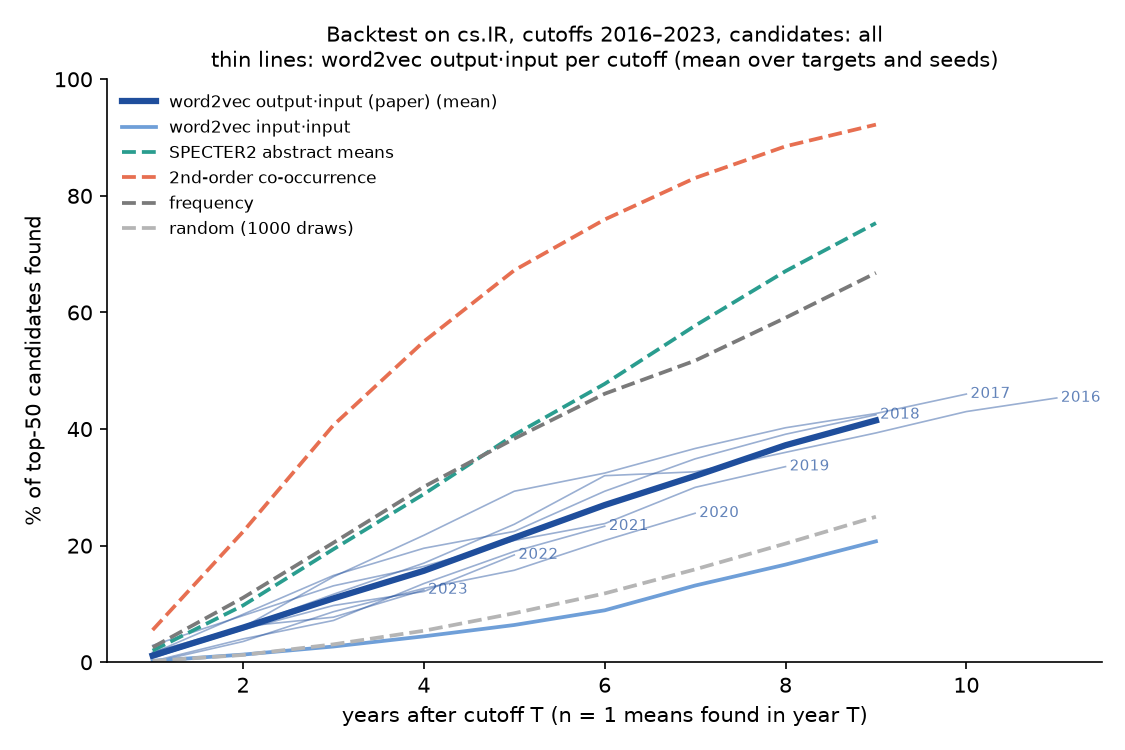

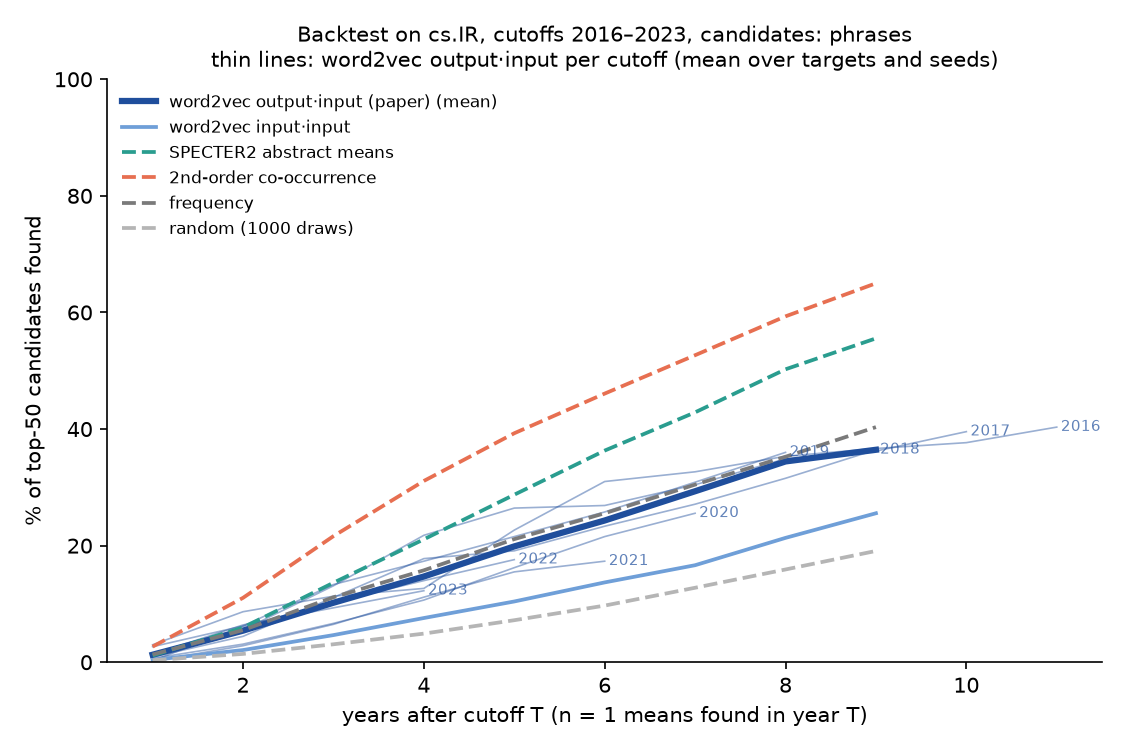

In [8]:
display(Image(F / 'fig3a_all.png'))
display(Image(F / 'fig3a_phrases.png'))

### Leakage check: with and without the version filter (professor's point 3)
`python ir2/scripts/phase2_preprocess.py --skip-docs --no-version-filter && python ir2/scripts/phase3_train.py --variant all_versions && python ir2/scripts/phase3_backtest.py --variant all_versions && python ir2/scripts/phase3_report.py --variant all_versions`

In [9]:
show('leakage_comparison.md')

# Leakage check: main run vs all-versions run

Main run: pre-T text = papers whose first and latest version are before T. All-versions run: first version before T only, so abstracts revised in or after T are included.

| T | pre-T docs (all versions) | removed by the filter | share |
|---|--:|--:|--:|
| 2016 | 6,042 | 298 | 4.9% |
| 2017 | 8,125 | 443 | 5.5% |
| 2018 | 11,089 | 576 | 5.2% |
| 2019 | 15,655 | 862 | 5.5% |
| 2020 | 22,179 | 1,310 | 5.9% |
| 2021 | 30,682 | 1,848 | 6.0% |
| 2022 | 40,285 | 2,089 | 5.2% |
| 2023 | 50,910 | 2,424 | 4.8% |

### Candidates `all`: mean P@k over the 28 pairs scored in both runs

| method | P@10 main | P@10 all versions | P@20 main | P@20 all versions | P@50 main | P@50 all versions |
|---|:-:|:-:|:-:|:-:|:-:|:-:|
| word2vec output·input (paper) | 0.252 ± 0.011 | 0.240 ± 0.011 | 0.277 ± 0.010 | 0.262 ± 0.009 | 0.279 ± 0.006 | 0.269 ± 0.001 |
| word2vec input·input | 0.094 ± 0.005 | 0.092 ± 0.009 | 0.094 ± 0.011 | 0.102 ± 0.012 | 0.104 ± 0.003 | 0.102 ± 0.003 |
| SPECTER2 abstract means | 0.529 | 0.496 | 0.491 | 0.479 | 0.467 | 0.442 |
| 2nd-order co-occurrence | 0.800 | 0.800 | 0.791 | 0.777 | 0.760 | 0.747 |
| frequency | 0.457 | 0.454 | 0.475 | 0.452 | 0.513 | 0.504 |
| random (1000 draws) | 0.138 | 0.129 | 0.137 | 0.130 | 0.137 | 0.130 |

### Candidates `phrases`: mean P@k over the 28 pairs scored in both runs

| method | P@10 main | P@10 all versions | P@20 main | P@20 all versions | P@50 main | P@50 all versions |
|---|:-:|:-:|:-:|:-:|:-:|:-:|
| word2vec output·input (paper) | 0.298 ± 0.027 | 0.283 ± 0.022 | 0.280 ± 0.019 | 0.253 ± 0.009 | 0.254 ± 0.002 | 0.239 ± 0.005 |
| word2vec input·input | 0.180 ± 0.005 | 0.173 ± 0.008 | 0.158 ± 0.006 | 0.152 ± 0.002 | 0.155 ± 0.003 | 0.142 ± 0.005 |
| SPECTER2 abstract means | 0.479 | 0.479 | 0.429 | 0.427 | 0.362 | 0.349 |
| 2nd-order co-occurrence | 0.596 | 0.575 | 0.561 | 0.530 | 0.475 | 0.454 |
| frequency | 0.368 | 0.375 | 0.337 | 0.330 | 0.281 | 0.271 |
| random (1000 draws) | 0.103 | 0.098 | 0.102 | 0.099 | 0.102 | 0.098 |

### Hero list (chosen after seeing every pair)

In [10]:
show('hero_top20.md')

# Hero list: `learning_to_rank`, cutoff T = 2020, candidates `phrases`

Trained on cs.IR ∪ cs.CL abstracts before 2020. Candidates never appear in an abstract with a `learning_to_rank` indicator before 2020. ✓ = appears with an indicator in ≥ 3 cs.IR abstracts from 2020 on (year the third one appeared).

| rank | word2vec output·input (paper) | found | frequency baseline | found |
|:-:|---|:-:|---|:-:|
| 1 | `multi_armed_bandit` | ✗ | `sentiment_analysis` | ✗ |
| 2 | `personalized_ranking` | ✓ 2024 | `neural_machine_translation` | ✗ |
| 3 | `matrix_factorisation` | ✗ | `speech_recognition` | ✗ |
| 4 | `fairness_aware` | ✗ | `cross_lingual` | ✓ 2025 |
| 5 | `root_mean_square_error` | ✗ | `language_modeling` | ✓ 2024 |
| 6 | `directly_optimizes` | ✗ | `recurrent_neural_networks` | ✗ |
| 7 | `latent_factor` | ✗ | `relation_extraction` | ✗ |
| 8 | `outperforms_state_of_the_art` | ✓ 2023 | `information_extraction` | ✗ |
| 9 | `meta_learning` | ✗ | `character_level` | ✗ |
| 10 | `negative_sampling` | ✓ 2024 | `named_entity_recognition` | ✗ |
| 11 | `recommendation_algorithms` | ✓ 2024 | `word_representations` | ✗ |
| 12 | `large_margin` | ✓ 2025 | `topic_modeling` | ✗ |
| 13 | `page_rank` | ✗ | `text_generation` | ✗ |
| 14 | `linear_regression` | ✗ | `sentiment_classification` | ✗ |
| 15 | `bandit_feedback` | ✗ | `encoder_decoder` | ✗ |
| 16 | `state_of_the_art_baselines` | ✓ 2026 | `neural_machine_translation_nmt` | ✗ |
| 17 | `rating_prediction` | ✗ | `nlp_tasks` | ✗ |
| 18 | `ctr_prediction` | ✓ 2022 | `semantic_parsing` | ✗ |
| 19 | `euclidean_distance` | ✗ | `low_resource` | ✗ |
| 20 | `link_prediction` | ✗ | `rule_based` | ✗ |

word2vec: 7/20 found · frequency: 2/20 found


### Correctness checks
`python ir2/scripts/phase3_checks.py`

In [11]:
show('backtest_checks.md')

# Backtest correctness checks (main run)

Recomputed from the raw normalized text, re-phrased with each cutoff's phraser (independent of the document × term matrices the backtest uses). Script: `scripts/phase3_checks.py`.

## 1. No post-T text in training

Every training abstract of every cutoff has first and latest version before T: **PASS**.

## 2. Candidates are new

4,787 distinct top-50 terms (word2vec seed 0 and frequency, both candidate sets, all 28 scored pairs) were searched in every pre-T abstract with an indicator. Terms found there: **0** → **PASS**.

## 3. "Found" is real

### Hero pair: `learning_to_rank`, T = 2020, candidates `phrases` (word2vec top 20, seed 0)

For each term: post-T cs.IR abstracts containing both the term and an indicator. ✓ requires ≥ 3; the recorded year must be the year of the 3rd.

| rank | term | recorded | recount | first 3 abstracts (arXiv id, year) | check |
|:-:|---|:-:|:-:|---|:-:|
| 1 | `multi_armed_bandit` | ✗ | 2 | 2108.03440 (2021), 2311.04528 (2023) | PASS |
| 2 | `personalized_ranking` | ✓ 2024 | 3 | 2102.07279 (2021), 2107.13876 (2021), 2406.15983 (2024) | PASS |
| 3 | `matrix_factorisation` | ✗ | 0 | — | PASS |
| 4 | `fairness_aware` | ✗ | 1 | 2503.21092 (2025) | PASS |
| 5 | `root_mean_square_error` | ✗ | 0 | — | PASS |
| 6 | `directly_optimizes` | ✗ | 2 | 2011.00550 (2020), 2511.00530 (2025) | PASS |
| 7 | `latent_factor` | ✗ | 1 | 2206.05368 (2022) | PASS |
| 8 | `outperforms_state_of_the_art` | ✓ 2023 | 9 | 2207.11785 (2022), 2303.04712 (2023), 2304.11043 (2023) | PASS |
| 9 | `meta_learning` | ✗ | 1 | 2409.19548 (2024) | PASS |
| 10 | `negative_sampling` | ✓ 2024 | 7 | 2105.04769 (2021), 2307.14906 (2023), 2405.07920 (2024) | PASS |
| 11 | `recommendation_algorithms` | ✓ 2024 | 5 | 2005.12977 (2020), 2108.03440 (2021), 2405.00824 (2024) | PASS |
| 12 | `large_margin` | ✓ 2025 | 3 | 2206.00473 (2022), 2407.07181 (2024), 2507.02255 (2025) | PASS |
| 13 | `page_rank` | ✗ | 0 | — | PASS |
| 14 | `linear_regression` | ✗ | 1 | 2002.07651 (2020) | PASS |
| 15 | `bandit_feedback` | ✗ | 0 | — | PASS |
| 16 | `state_of_the_art_baselines` | ✓ 2026 | 3 | 2002.09841 (2020), 2511.00530 (2025), 2609.35041 (2026) | PASS |
| 17 | `rating_prediction` | ✗ | 0 | — | PASS |
| 18 | `ctr_prediction` | ✓ 2022 | 5 | 2007.06434 (2020), 2208.06164 (2022), 2210.10725 (2022) | PASS |
| 19 | `euclidean_distance` | ✗ | 0 | — | PASS |
| 20 | `link_prediction` | ✗ | 1 | 2409.16590 (2024) | PASS |

20/20 rows agree with the recount.

### Random sample: 60 top-50 terms (word2vec seed 0) from all scored pairs

18 recorded as found, 42 as not found. Agreement with the recount: **60/60** → **PASS**.

## 4. Random equals the base rate

Over 56 (pair, candidate set) rows, |random P@50 − base rate| is at most 0.0049 (mean 0.0013): **PASS** (threshold 0.01).

## 5. Seeds differ

word2vec P@50 is identical across the 3 seeds in 3/56 (pair, candidate set) rows; the mean std across seeds is 0.027. The seeds are applied, and the spread is small. Identical values in a few rows are expected: P@50 moves in steps of 0.02.


## Phase 4: embedding timeline of cs.IR
`python ir2/scripts/phase4_timeline.py`

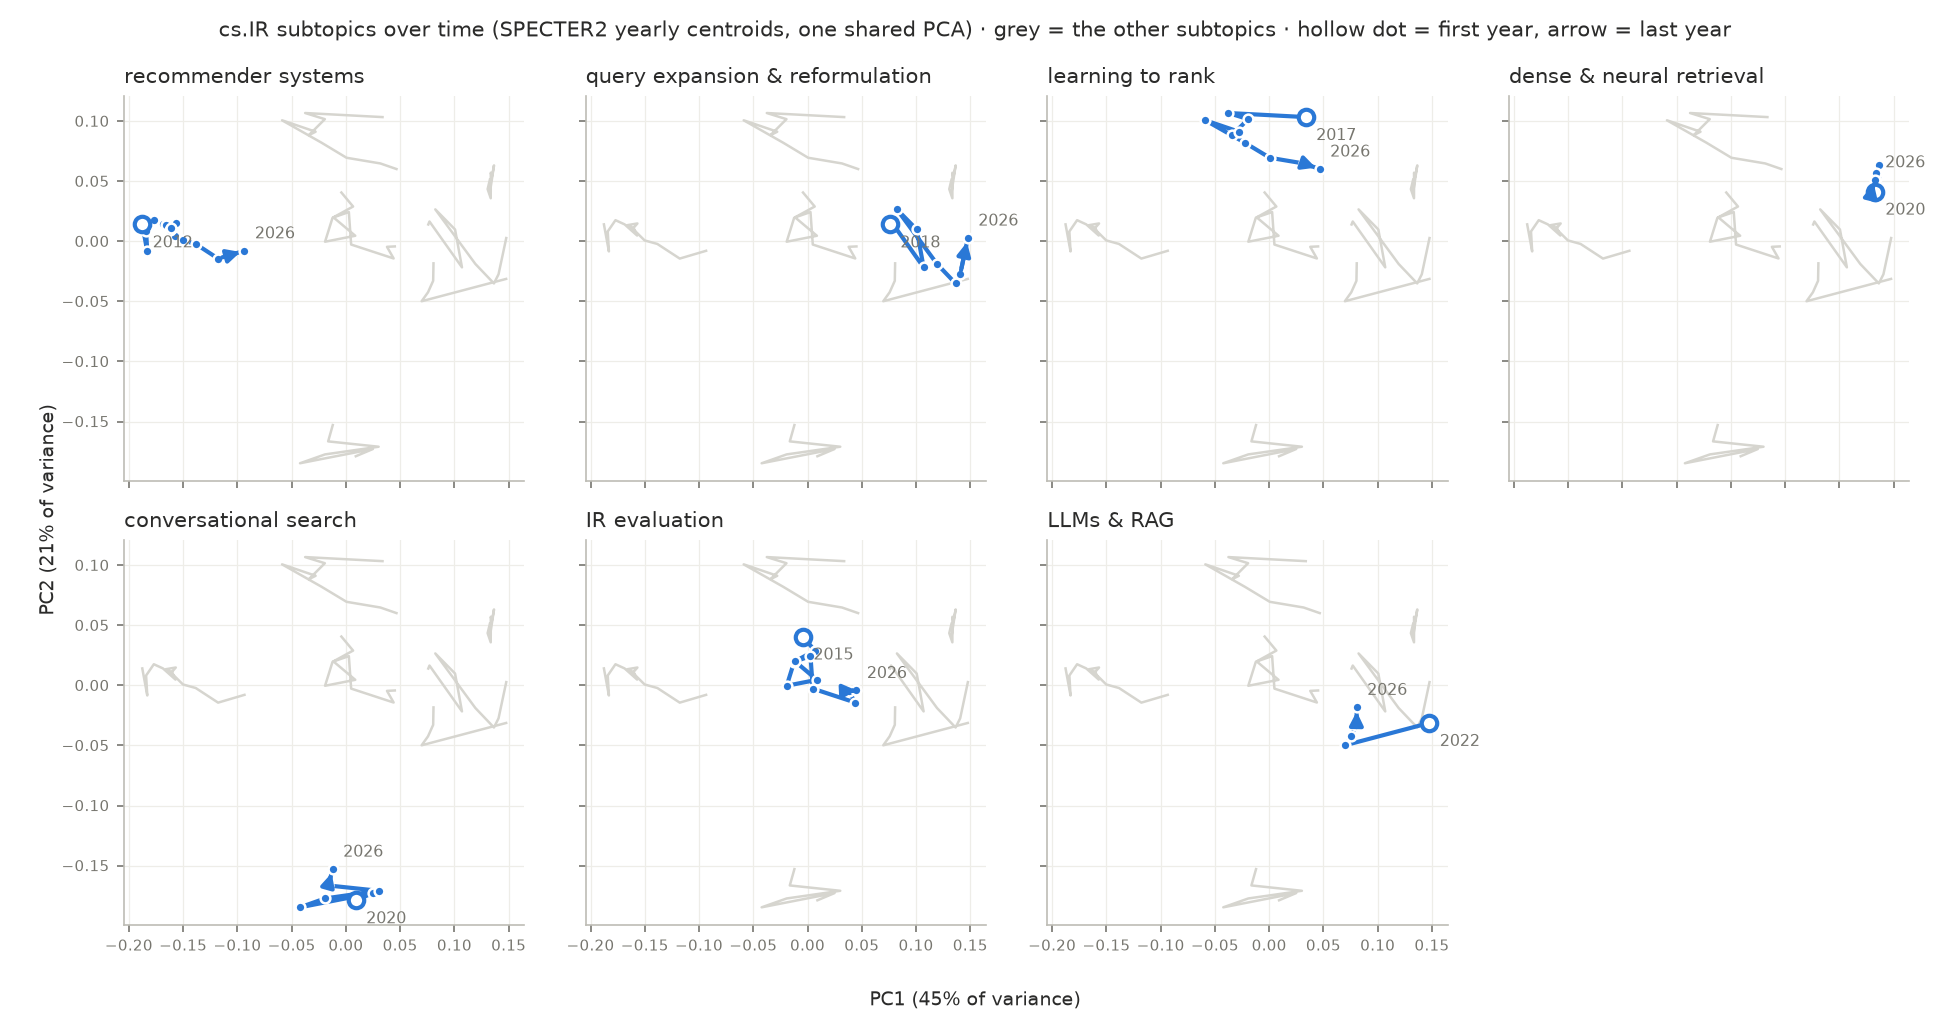

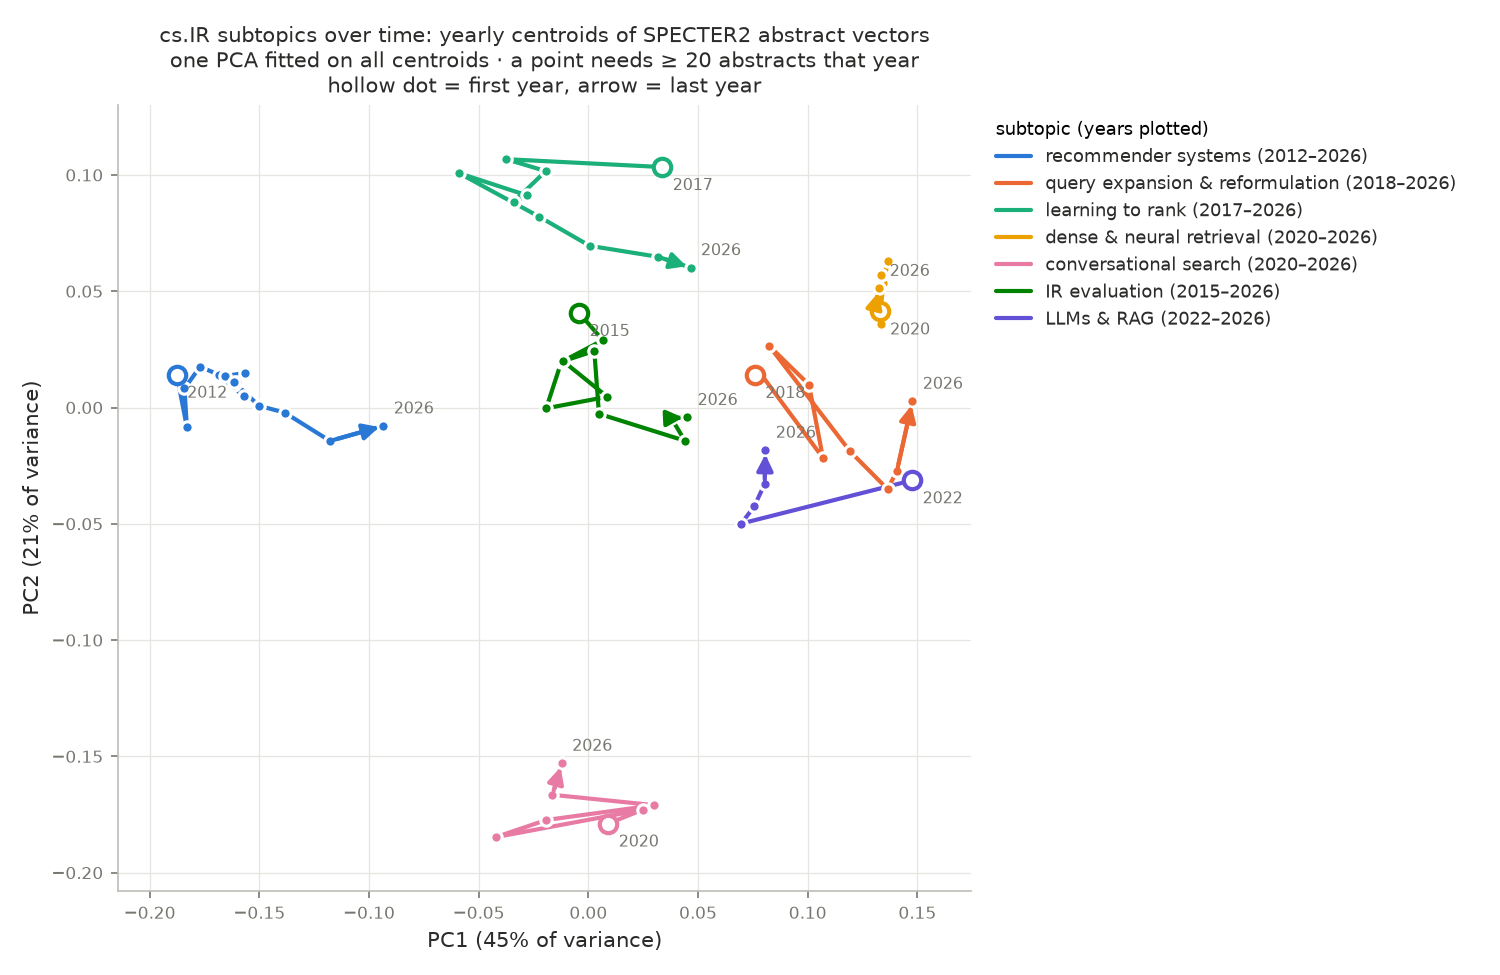

# Phase 4: embedding timeline of cs.IR

Subtopics are keyword sets matched on cs.IR abstracts (first-version year; an abstract can belong to several). A point = the mean SPECTER2 vector of a subtopic's abstracts in one year, kept only with ≥ 20 abstracts. Figures: `figures/timeline_specter2_panels.png` (one panel per subtopic) and `figures/timeline_specter2.png` (overview). Caveat: SPECTER2 was pretrained on recent papers.

Similarities below are cosines of centroids **minus the mean cs.IR abstract vector**: raw SPECTER2 centroids all have cosine 0.95–0.99 with each other, because all abstracts share a common direction. Centering does not change the PCA plot.

## A. SPECTER2 centroids

One PCA on all 64 centroids: PC1 explains 44.8% and PC2 20.9% of their variance (65.7% together). The 2-D plot is a projection; distances below are in the full space.

| subtopic | keywords | first year | last year | abstracts (first → last year) | centered cosine first↔last centroid |
|---|---|:-:|:-:|:-:|:-:|
| recommender systems | recommender, recommenders, recommendation, recommendations, collaborative filtering | 2012 | 2026 | 64 → 1388 | 0.43 |
| query expansion & reformulation | query expansion, query reformulation, query rewriting, query suggestion, relevance feedback | 2018 | 2026 | 25 → 111 | 0.55 |
| learning to rank | learning to rank, ranknet, lambdamart, lambdarank, listwise, pairwise ranking | 2017 | 2026 | 20 → 88 | 0.55 |
| dense & neural retrieval | dense retrieval, dense retriever, dense retrievers, dense passage retrieval, dual encoder, dual encoders, bi encoder, bi encoders, neural ranking, neural retrieval, colbert | 2020 | 2026 | 28 → 295 | 0.73 |
| conversational search | conversational search, conversational recommendation, conversational recommender, clarifying question, clarifying questions, conversational information seeking | 2020 | 2026 | 33 → 51 | 0.83 |
| IR evaluation | test collection, test collections, relevance judgments, relevance judgements, relevance assessments, evaluation metrics, evaluation measures, offline evaluation, cranfield | 2015 | 2026 | 22 → 119 | 0.11 |
| LLMs & RAG | large language model, large language models, llm, llms, retrieval augmented, rag | 2022 | 2026 | 29 → 2323 | 0.69 |

### Centered cosine similarity between subtopic centroids, by year

| pair | 2012 | 2013 | 2014 | 2015 | 2016 | 2017 | 2018 | 2019 | 2020 | 2021 | 2022 | 2023 | 2024 | 2025 | 2026 |
|---|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| dense & neural retrieval ↔ LLMs & RAG | — | — | — | — | — | — | — | — | — | — | 0.68 | 0.48 | 0.58 | 0.62 | 0.71 |
| query expansion & reformulation ↔ LLMs & RAG | — | — | — | — | — | — | — | — | — | — | 0.45 | 0.59 | 0.70 | 0.80 | 0.78 |
| query expansion & reformulation ↔ dense & neural retrieval | — | — | — | — | — | — | — | — | 0.49 | 0.71 | 0.69 | 0.75 | 0.81 | 0.79 | 0.87 |
| recommender systems ↔ conversational search | — | — | — | — | — | — | — | — | 0.03 | 0.03 | 0.31 | 0.35 | 0.12 | 0.46 | 0.48 |
| learning to rank ↔ dense & neural retrieval | — | — | — | — | — | — | — | — | 0.24 | 0.28 | 0.08 | 0.23 | 0.40 | 0.52 | 0.66 |
| recommender systems ↔ LLMs & RAG | — | — | — | — | — | — | — | — | — | — | -0.47 | -0.19 | -0.25 | -0.13 | 0.05 |

### Points per subtopic and year (abstracts)

| subtopic                        |   2012 |   2013 |   2014 |   2015 |   2016 |   2017 |   2018 |   2019 |   2020 |   2021 |   2022 |   2023 |   2024 |   2025 |   2026 |
|:--------------------------------|-------:|-------:|-------:|-------:|-------:|-------:|-------:|-------:|-------:|-------:|-------:|-------:|-------:|-------:|-------:|
| IR evaluation                   |      0 |      0 |      0 |     22 |      0 |     31 |     38 |     50 |     52 |     59 |     74 |     90 |    125 |    147 |    119 |
| LLMs & RAG                      |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |     29 |    358 |   1322 |   2067 |   2323 |
| conversational search           |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |     33 |     37 |     39 |     60 |     68 |     65 |     51 |
| dense & neural retrieval        |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |     28 |     83 |    111 |    145 |    161 |    207 |    295 |
| learning to rank                |      0 |      0 |      0 |      0 |      0 |     20 |     39 |     39 |     60 |     56 |     53 |     70 |     78 |     85 |     88 |
| query expansion & reformulation |      0 |      0 |      0 |      0 |      0 |      0 |     25 |     25 |     34 |     30 |     23 |     44 |     54 |     88 |    111 |
| recommender systems             |     64 |     74 |     75 |     91 |    143 |    223 |    340 |    478 |    600 |    745 |    849 |   1127 |   1382 |   1454 |   1388 |

### Robustness of the 2-D layout

Procrustes disparity between the main layout and a refit on a variant, on their common points (0 = identical shape up to rotation, scaling and reflection; 1 = unrelated).

| variant | common points | disparity |
|---|:-:|:-:|
| without 2026 (partial year) | 57 | 0.000 |
| ≥ 50 abstracts per point | 47 | 0.002 |

## B. word2vec: neighbours and movement across cutoffs (seed 0)

Spaces of different cutoffs are not aligned, so each pair of consecutive cutoffs is aligned by orthogonal Procrustes on the normalized input vectors of their shared vocabulary (HistWords). *Self-similarity* = cosine between a word's aligned vector at T and its vector at the next cutoff; lower = the word's usage moved more. It is compared with the median over all shared words.

| concept | 2016→2017 | 2017→2018 | 2018→2019 | 2019→2020 | 2020→2021 | 2021→2022 | 2022→2023 |
|---|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| `query_expansion` | 0.90 | 0.93 | 0.91 | 0.91 | 0.89 | 0.91 | 0.92 |
| `recommender` | 0.86 | 0.85 | 0.83 | 0.81 | 0.83 | 0.91 | 0.94 |
| `learning_to_rank` | 0.89 | 0.91 | 0.88 | 0.88 | 0.89 | 0.89 | 0.92 |
| `retrieval` | 0.86 | 0.90 | 0.88 | 0.90 | 0.90 | 0.91 | 0.94 |
| *median word* | 0.90 | 0.89 | 0.89 | 0.89 | 0.90 | 0.91 | 0.92 |

Nearest neighbours (input vectors, top 8, terms in the candidate vocabulary):

**`query_expansion`**

| T | neighbours |
|---|---|
| 2016 | bradfordizing, proposes_a_new, reformulating, refining, categorisation, enriches, bayesum, original_query |
| 2017 | aqe, bradfordizing, query_reformulation, proposes_a_new, enriches, relevance_feedback, reformulating, pseudo |
| 2018 | aqe, bradfordizing, query_reformulation, relevance_feedback, bayesum, finder, vocabulary_mismatch, expansion |
| 2019 | pseudo_relevance_feedback, aqe, bradfordizing, prf, bm25f, term_weighting, gsa, textrank |
| 2020 | aqe, pseudo_relevance_feedback, bradfordizing, prf, expansion_terms, keyphrase_extraction, elasticsearch, passage_retrieval |
| 2021 | pseudo_relevance_feedback, aqe, prf, bradfordizing, search, retrieval, set_expansion, okapi |
| 2022 | aqe, pseudo_relevance_feedback, prf, manifold_ranking, vocabulary_mismatch, bradfordizing, deepimpact, ceqe |
| 2023 | pseudo_relevance_feedback, pseudo_relevance_feedback_prf, term_suggestion, aqe, bradfordizing, query_reformulation, ceqe, deepimpact |

**`recommender`**

| T | neighbours |
|---|---|
| 2016 | recommendation, recommenders, clothes, collaborative_filtering_cf, rating_prediction, tour, recommendations, crs |
| 2017 | recommendation, recommendations, recommenders, recommender_systems, collaborative_filtering, clothes, collaborative_filtering_cf, coined |
| 2018 | recommendation, recommender_systems, recommendations, collaborative_filtering, dlib, recommends, collaborative_filtering_cf, middleware |
| 2019 | recommendation, recommender_systems, recommenders, collaborative_filtering, afel, rec, recommendation_algorithms, recommendations |
| 2020 | recommendation, recommendations, recommender_systems, collaborative_filtering, recommendation_systems, recommenders, recommendation_algorithms, collaborative_filtering_cf |
| 2021 | recommendation, recommendations, recommender_systems, recommenders, collaborative_filtering, recommendation_systems, hybrid_recommender, collaborative_filtering_cf |
| 2022 | recommendation, recommender_systems, recommendations, collaborative_filtering, recommenders, recommendation_systems, collaborative_filtering_cf, personalized_recommendation |
| 2023 | recommendation, recommender_systems, recommendations, recommenders, collaborative_filtering, recommendation_systems, movie_recommender, personalized_recommendation |

**`learning_to_rank`**

| T | neighbours |
|---|---|
| 2016 | bagging, rank_aggregation, adaboost, probfuse, mcf, implicit_feedback, benchmark_data_sets, ccf |
| 2017 | adaboost, l2r, ltr, bagging, lambdamart, rank_aggregation, regularized, mcf |
| 2018 | ltr, l2r, listwise, ranking, hcf, bpr, bm25, bm25f |
| 2019 | ltr, ranking, listwise, personalized_ranking, ranking_functions, rankers, ncr, gemrank |
| 2020 | ranking, letor, unbiased_learning_to_rank, ranking_functions, learning_to_rank_ltr, list_wise, bpr, listwise |
| 2021 | learning_to_rank_ltr, ranking, unbiased_learning_to_rank, list_wise, listwise, letor, plackett, gams |
| 2022 | ranking, learning_to_rank_ltr, letor, list_wise, listwise, plackett, rank_aggregation, ranking_functions |
| 2023 | learning_to_rank_ltr, ranking, listwise, letor, unbiased_learning_to_rank, ltr, list_wise, bayesian_personalized |

**`retrieval`**

| T | neighbours |
|---|---|
| 2016 | cross_media, fusing, bm25, subregions, birds, fusion, passage, probfuse |
| 2017 | cross_media, humming, subregions, cbvr, fusing, retrieving, zettair, eeg |
| 2018 | subregions, cross_media, cbvr, indexing_and_retrieval, humming, search, probfuse, document_retrieval |
| 2019 | subregions, search, mias, retrieving, pseudo_relevance_feedback, cbvr, lucene, probfuse |
| 2020 | search, vitrivr, prior_art, mias, subregions, query, nohis, cross_media |
| 2021 | matching, search, passage_retrieval, document_retrieval, vitrivr, pseudo_relevance_feedback, indexing_and_retrieval, query |
| 2022 | document_retrieval, matching, search, dense_passage, retrieving, vitrivr, retriever_reader, query |
| 2023 | parm, document_retrieval, search, matching, query, vitrivr, retrieving, dense_passage_retrieval |


In [12]:
display(Image(F / 'timeline_specter2_panels.png'))
display(Image(F / 'timeline_specter2.png'))
show('timeline.md')